# Milestone 2, Part 2: retraining the classifier with synthetic images

**Goal:** test whether the images generated in Part 1 help the Milestone 1 classifier on the rare DermaMNIST classes, and compare this with the two standard fixes for class imbalance: class-weighted loss and oversampling.

The four setups differ in one thing only:

| Arm | What changes |
|---|---|
| Baseline | nothing (the Milestone 1 classifier) |
| Class-weighted loss | cross-entropy with class weights w_c = N / (K·n_c) |
| Oversampling | training images drawn with probability ∝ 1 / n_class |
| + Synthetic | every class except nv topped up to 1,000 images with generated images |

**Outline of the notebook:**

1. Setup: libraries, Google Drive, paths.
2. Configuration: the shared training settings.
3. Data: real splits, generated images, and the top-up.
4. The four training sets.
5. Training and evaluation functions.
6. Run the four arms with 3 seeds each.
7. Results: tables and per-class recall.

## 1. Setup

Clone the official MedMNIST experiments repository, which contains the ResNet-18 used in Milestone 1, and install the `medmnist` package.

In [1]:
!git clone -q https://github.com/MedMNIST/experiments.git /content/experiments 2>/dev/null || echo "already cloned"
!pip install -q medmnist

Imports. The metrics `getAUC` and `getACC` and the `ResNet18` model come from the MedMNIST code, so the results are directly comparable with Milestone 1. Google Drive is mounted to read the generated images and to save the results.

In [2]:
import os, sys, json, math, time, copy, glob
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score

import medmnist
from medmnist import DermaMNIST
from medmnist.evaluator import getAUC, getACC     # same metric functions as the official script

sys.path.insert(0, "/content/experiments/MedMNIST2D")
from models import ResNet18                        # same ResNet-18 as Milestone 1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| medmnist", medmnist.__version__, "| device", device)

from google.colab import drive
drive.mount("/content/drive")

torch 2.14.1+cu130 | medmnist 3.0.2 | device cuda
Mounted at /content/drive


Paths. `POOL` is the file of generated images from Part 1. Each training run is saved as a JSON file in `part2_classifier/runs/`.

In [3]:
PROJECT = "/content/drive/MyDrive/deep_learning_project"
POOL = f"{PROJECT}/Milestone_2/split_original_run_second_run/synthetic_pool_w0.3.npz"   # generated in Part 1
OUT  = f"{PROJECT}/Milestone_2/part2_classifier"
os.makedirs(f"{OUT}/runs", exist_ok=True)
assert os.path.exists(POOL), f"pool not found: {POOL}"

## 2. Config

Everything is identical across paths except the one thing each arm changes. The classifier settings are those of Milestone 1 (official MedMNIST script): ResNet-18, inputs in [−1, 1], Adam lr 1e-3, batch 128, 100 epochs, LR ×0.1 at 50 % and 75 %, no augmentation, checkpoint with the best validation AUC. Every arm gets the same number of gradient steps (100 × 55 = 5,500), so the synthetic arm gets no extra compute. Validation and test sets are 100 % real.

In [4]:
CFG = dict(
    lr=1e-3, batch_size=128, ref_epochs=100, milestones_frac=(0.5, 0.75), gamma=0.1,
    amp=True,                                   # mixed precision: faster on a T4
    seeds=[0, 1, 2],
    arms=["baseline", "weighted", "oversample", "synthetic"],
    synth_classes=[0, 1, 2, 3, 4, 6],           # every class except nv
    synth_target=1000,                          # topped up to this many images (real + synthetic)
    rare_classes=[0, 1, 3, 6],                  # akiec, bcc, df, vasc (used for the rare-class recall metric)
)
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

## 3. Data: real splits and synthetic images

Load the three real splits and the generated images, and choose the images to add:

- Every class except nv is topped up to 1,000 training images. The number added per class is 1,000 minus the number of real images: from +221 for mel to +920 for df.
- The first N generated images of each class are used.
- The validation and test sets stay 100 % real. Generated images are only ever used for training.

In [5]:
def load_split(split):
    ds = DermaMNIST(split=split, size=28, download=True)
    return ds.imgs.astype(np.uint8), ds.labels.reshape(-1).astype(np.int64)

real = {s: load_split(s) for s in ["train", "val", "test"]}
for s, (x, y) in real.items():
    print(f"{s:5s} {x.shape}  counts {np.bincount(y, minlength=7).tolist()}")

pool = np.load(POOL)
pool_x, pool_y = pool["imgs"], pool["labels"].astype(np.int64)
print("synthetic pool", pool_x.shape, "counts", np.bincount(pool_y, minlength=7).tolist())

def to_gpu_float(x_uint8):
    """uint8 NHWC → float NCHW in [-1, 1] (= ToTensor + Normalize(0.5, 0.5))."""
    x = torch.from_numpy(x_uint8).to(device).permute(0, 3, 1, 2).float() / 255.0
    return (x - 0.5) / 0.5

# synthetic top-up: the first N generated images of each class
n_train = np.bincount(real["train"][1], minlength=7)
synth_idx, synth_add = [], {}
for c in CFG["synth_classes"]:
    need = max(0, CFG["synth_target"] - int(n_train[c]))
    synth_idx.append(np.flatnonzero(pool_y == c)[:need]); synth_add[CLASSES[c]] = need
synth_idx = np.concatenate(synth_idx)
print("synthetic images added:", synth_add, "| total", len(synth_idx))

100%|██████████| 19.7M/19.7M [00:18<00:00, 1.05MB/s]


train (7007, 28, 28, 3)  counts [228, 359, 769, 80, 779, 4693, 99]
val   (1003, 28, 28, 3)  counts [33, 52, 110, 12, 111, 671, 14]
test  (2005, 28, 28, 3)  counts [66, 103, 220, 23, 223, 1341, 29]
synthetic pool (6000, 28, 28, 3) counts [1000, 1000, 1000, 1000, 1000, 0, 1000]
synthetic images added: {'akiec': 772, 'bcc': 641, 'bkl': 231, 'df': 920, 'mel': 221, 'vasc': 901} | total 3686


Real and generated training images side by side, one row per class. The generated images reproduce the typical colours and shapes of each class.

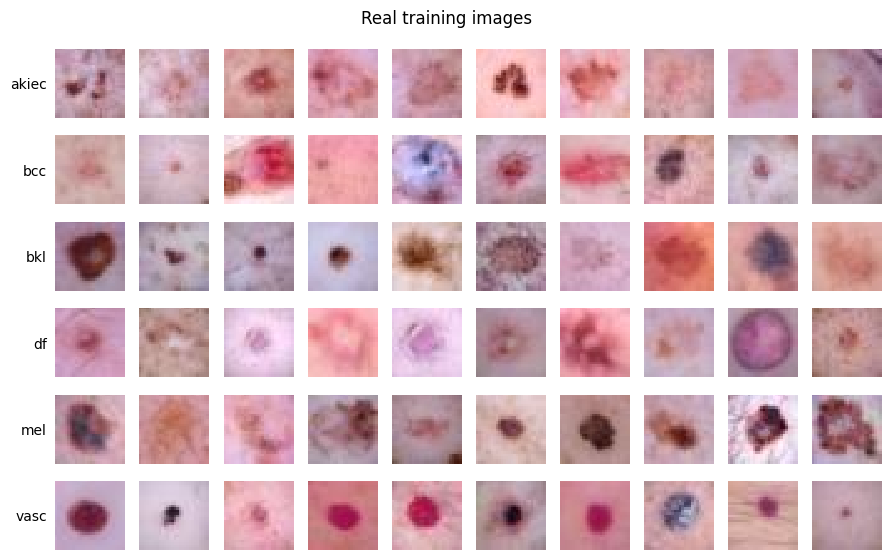

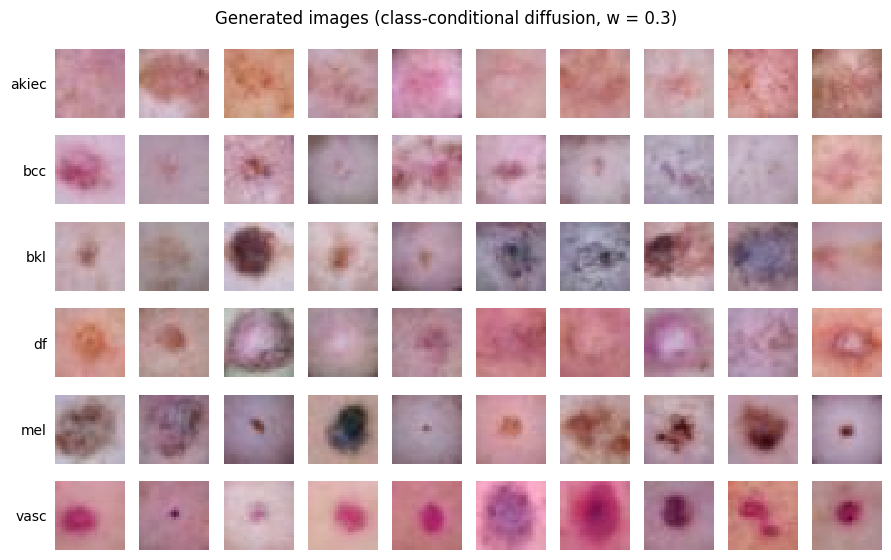

In [6]:
def show_grid(x_uint8, y, classes_to_show, per_class=10, seed=0, title="", save_path=None):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(len(classes_to_show), per_class, figsize=(per_class * 0.9, len(classes_to_show) * 0.95))
    for r, c in enumerate(classes_to_show):
        idx = rng.choice(np.flatnonzero(y == c), size=per_class, replace=False)
        for k, i in enumerate(idx):
            axes[r, k].imshow(x_uint8[i], interpolation="nearest"); axes[r, k].axis("off")
        axes[r, 0].text(-4, 14, CLASSES[c], ha="right", va="center", fontsize=10)
    fig.suptitle(title); plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

show_grid(*real["train"], CFG["synth_classes"], title="Real training images", save_path=f"{OUT}/grid_real.png")
show_grid(pool_x, pool_y, CFG["synth_classes"], title="Generated images (class-conditional diffusion, w = 0.3)", save_path=f"{OUT}/grid_synthetic.png")

## 4. The four training sets

`build_arm` returns the training set of each arm:

- baseline, weighted and oversample use the 7,007 real images. Weighted adds the class weights to the loss; oversample adds per-image sampling weights.
- synthetic adds the 3,686 generated images, for 10,693 images in total.

In [7]:
def build_arm(arm):
    xr, yr = real["train"]
    if arm == "synthetic":
        x, y = np.concatenate([xr, pool_x[synth_idx]]), np.concatenate([yr, pool_y[synth_idx]])
    else:
        x, y = xr, yr
    counts = np.bincount(y, minlength=7)
    class_w = torch.tensor(len(y) / (7 * counts), dtype=torch.float32, device=device) if arm == "weighted" else None
    sample_w = torch.tensor(1.0 / counts[y], dtype=torch.double) if arm == "oversample" else None
    return dict(x=to_gpu_float(x), y=torch.from_numpy(y).to(device), counts=counts, class_w=class_w, sample_w=sample_w)

for a in CFG["arms"]:
    d = build_arm(a)
    print(f"{a:10s} n={len(d['y']):6d}  class counts={d['counts'].tolist()}")
    del d

baseline   n=  7007  class counts=[228, 359, 769, 80, 779, 4693, 99]
weighted   n=  7007  class counts=[228, 359, 769, 80, 779, 4693, 99]
oversample n=  7007  class counts=[228, 359, 769, 80, 779, 4693, 99]
synthetic  n= 10693  class counts=[1000, 1000, 1000, 1000, 1000, 4693, 1000]


## 5. Training and evaluation

The training procedure is that of the official `train_and_eval_pytorch.py` used in Milestone 1, with the data kept on the GPU for speed:

- `predict` returns the class probabilities for a set of images.
- `metrics` computes AUC and accuracy (the Milestone 1 metrics), plus balanced accuracy, macro-F1, the recall of every class, and the mean recall of the 4 rare classes (akiec, bcc, df, vasc).
- `epoch_indices` gives the images of one epoch: a random shuffle for the uniform arms, or weighted sampling with replacement for oversampling.
- `run_one` trains one model. Every arm gets the same number of gradient steps (100 epochs × 55 steps), so the larger synthetic training set gets no extra compute. The checkpoint with the best validation AUC is evaluated on the test set.

In [8]:
val_x, val_y = to_gpu_float(real["val"][0]), real["val"][1]
test_x, test_y = to_gpu_float(real["test"][0]), real["test"][1]
AMP = CFG["amp"] and device.type == "cuda"

@torch.no_grad()
def predict(model, x, bs=1024):
    model.eval()
    out = []
    for i in range(0, len(x), bs):
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
            out.append(torch.softmax(model(x[i:i + bs]).float(), 1))
    return torch.cat(out).cpu().numpy()

def metrics(y_true, prob):
    pred = prob.argmax(1)
    rec = recall_score(y_true, pred, labels=range(7), average=None, zero_division=0)
    m = dict(auc=float(getAUC(y_true, prob, "multi-class")), acc=float(getACC(y_true, prob, "multi-class")),
             bal_acc=float(balanced_accuracy_score(y_true, pred)),
             macro_f1=float(f1_score(y_true, pred, average="macro", zero_division=0)))
    m.update({f"recall_{CLASSES[c]}": float(rec[c]) for c in range(7)})
    m["rare_recall_mean"] = float(np.mean([rec[c] for c in CFG["rare_classes"]]))
    return m

def epoch_indices(n_total, n_draw, sample_w, gen, buf):
    """Indices for one epoch: uniform shuffling, or weighted sampling with replacement (oversampling)."""
    if sample_w is not None:
        return torch.multinomial(sample_w, n_draw, replacement=True, generator=gen), buf
    while len(buf) < n_draw:
        buf = torch.cat([buf, torch.randperm(n_total, generator=gen)])
    return buf[:n_draw], buf[n_draw:]

def run_one(arm, seed, data):
    n_ref = len(real["train"][1])                                   # 7,007 → 55 steps per epoch for every arm
    total = CFG["ref_epochs"] * math.ceil(n_ref / CFG["batch_size"])
    torch.manual_seed(seed); np.random.seed(seed)
    model = ResNet18(in_channels=3, num_classes=7).to(device).to(memory_format=torch.channels_last)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[int(f * total) for f in CFG["milestones_frac"]], gamma=CFG["gamma"])
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    crit = nn.CrossEntropyLoss(weight=data["class_w"])
    gen, buf = torch.Generator().manual_seed(1000 + seed), torch.empty(0, dtype=torch.long)
    best_auc, best_state, best_epoch, t0 = -1, None, -1, time.time()
    for ep in range(CFG["ref_epochs"]):
        model.train()
        idx_epoch, buf = epoch_indices(len(data["y"]), n_ref, data["sample_w"], gen, buf)
        for b in range(0, n_ref, CFG["batch_size"]):
            idx = idx_epoch[b:b + CFG["batch_size"]].to(device)
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                loss = crit(model(data["x"][idx].contiguous(memory_format=torch.channels_last)), data["y"][idx])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        vauc = float(getAUC(val_y, predict(model, val_x), "multi-class"))
        if vauc > best_auc:                                          # model selection: best validation AUC
            best_auc, best_epoch, best_state = vauc, ep, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return dict(arm=arm, seed=seed, best_epoch=best_epoch, train_size=int(len(data["y"])),
                train_sec=time.time() - t0, test=metrics(test_y, predict(model, test_x)))

## 6. Run the four arms × 3 seeds

Each run takes about 3 minutes on a T4, so 12 runs take about 40 minutes. Each finished run is saved to Drive and skipped on re-run, so the loop is resumable.

The output below is from a session in which all 12 runs were already finished.

In [9]:
for arm in CFG["arms"]:
    data = build_arm(arm)
    for seed in CFG["seeds"]:
        path = f"{OUT}/runs/{arm}_seed{seed}.json"
        if os.path.exists(path):
            print(f"{arm} seed {seed}: done"); continue
        res = run_one(arm, seed, data)
        with open(path, "w") as f: json.dump(res, f)
        t = res["test"]
        print(f"{arm} seed {seed}: AUC {t['auc']:.3f} ACC {t['acc']:.3f} balACC {t['bal_acc']:.3f} "
              f"rare-recall {t['rare_recall_mean']:.3f} ({res['train_sec']/60:.1f} min)")
    del data; torch.cuda.empty_cache()

baseline seed 0: done
baseline seed 1: done
baseline seed 2: done
weighted seed 0: done
weighted seed 1: done
weighted seed 2: done
oversample seed 0: done
oversample seed 1: done
oversample seed 2: done
synthetic seed 0: done
synthetic seed 1: done
synthetic seed 2: done


## 7. Results

Test-set results, mean ± std over the 3 seeds:

- **AUC** and **ACC**: the Milestone 1 metrics. They are dominated by nv, which makes up 67 % of the test set.
- **Balanced accuracy** and **macro-F1**: every class counts equally.
- **rare_recall_mean**: the average recall of akiec, bcc, df and vasc, i.e. the share of rare-lesion images the model finds.

In [10]:
runs = [json.load(open(f"{OUT}/runs/{a}_seed{s}.json")) for a in CFG["arms"] for s in CFG["seeds"]]
flat = pd.DataFrame([dict(arm=r["arm"], seed=r["seed"], **r["test"]) for r in runs])

def mean_std(cols):
    g = flat.groupby("arm")[cols].agg(["mean", "std"]).reindex(CFG["arms"])
    return pd.DataFrame({c: [f"{m:.3f} ± {s:.3f}" for m, s in zip(g[(c, "mean")], g[(c, "std")])] for c in cols},
                        index=CFG["arms"])

table_main = mean_std(["auc", "acc", "bal_acc", "macro_f1", "rare_recall_mean"])
table_main.to_csv(f"{OUT}/results_main.csv")
print("Test set, mean ± std over 3 seeds (Milestone 1: AUC 0.914 ± 0.006, ACC 0.740 ± 0.016)")
table_main

Test set, mean ± std over 3 seeds (Milestone 1: AUC 0.914 ± 0.006, ACC 0.740 ± 0.016)


,auc,acc,bal_acc,macro_f1,rare_recall_mean
baseline,0.918 ± 0.002,0.741 ± 0.007,0.455 ± 0.042,0.477 ± 0.027,0.370 ± 0.070
weighted,0.902 ± 0.003,0.607 ± 0.024,0.558 ± 0.007,0.450 ± 0.024,0.528 ± 0.013
oversample,0.892 ± 0.003,0.683 ± 0.073,0.511 ± 0.055,0.498 ± 0.028,0.474 ± 0.094
synthetic,0.914 ± 0.004,0.733 ± 0.007,0.515 ± 0.013,0.502 ± 0.003,0.501 ± 0.020


Recall of each class. This shows which classes each fix helps, and which ones it hurts.

In [11]:
rec_cols = [f"recall_{c}" for c in CLASSES]
table_recall = mean_std(rec_cols); table_recall.columns = CLASSES
table_recall.to_csv(f"{OUT}/results_per_class_recall.csv")
print("Per-class test recall | test images per class:", dict(zip(CLASSES, np.bincount(test_y, minlength=7).tolist())))
table_recall

Per-class test recall | test images per class: {'akiec': 66, 'bcc': 103, 'bkl': 220, 'df': 23, 'mel': 223, 'nv': 1341, 'vasc': 29}


,akiec,bcc,bkl,df,mel,nv,vasc
baseline,0.369 ± 0.075,0.456 ± 0.093,0.412 ± 0.042,0.101 ± 0.066,0.384 ± 0.160,0.910 ± 0.036,0.552 ± 0.172
weighted,0.364 ± 0.084,0.495 ± 0.076,0.452 ± 0.039,0.507 ± 0.066,0.709 ± 0.021,0.635 ± 0.040,0.747 ± 0.072
oversample,0.394 ± 0.114,0.492 ± 0.048,0.382 ± 0.123,0.333 ± 0.165,0.501 ± 0.209,0.797 ± 0.140,0.678 ± 0.080
synthetic,0.535 ± 0.076,0.414 ± 0.040,0.391 ± 0.074,0.319 ± 0.025,0.306 ± 0.036,0.901 ± 0.021,0.736 ± 0.087


The same per-class recall as a bar chart, with the seed standard deviation as error bars.

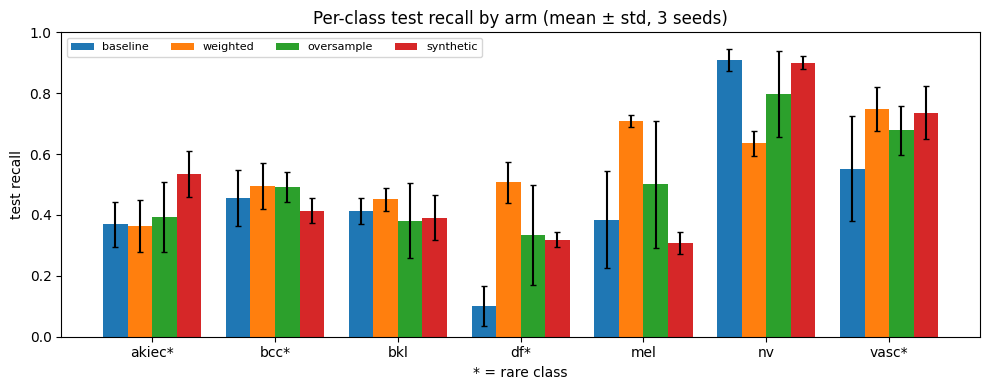

In [12]:
g = flat.groupby("arm")[rec_cols].agg(["mean", "std"]).reindex(CFG["arms"])
xpos, wbar = np.arange(7), 0.8 / len(CFG["arms"])
fig, ax = plt.subplots(figsize=(10, 4))
for i, a in enumerate(CFG["arms"]):
    ax.bar(xpos + i * wbar - 0.4 + wbar / 2, g.loc[a, [(c, "mean") for c in rec_cols]], wbar,
           yerr=g.loc[a, [(c, "std") for c in rec_cols]], capsize=2, label=a)
ax.set_xticks(xpos); ax.set_xticklabels([c + ("*" if k in CFG["rare_classes"] else "") for k, c in enumerate(CLASSES)])
ax.set_xlabel("* = rare class"); ax.set_ylabel("test recall"); ax.set_ylim(0, 1)
ax.legend(ncol=4, fontsize=8); ax.set_title("Per-class test recall by arm (mean ± std, 3 seeds)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_per_class_recall.png", dpi=200, bbox_inches="tight"); plt.show()

## Summary

**Baseline.** Our training loop reproduces Milestone 1: test AUC 0.918 ± 0.002 and ACC 0.741 ± 0.007, against 0.914 ± 0.006 / 0.740 ± 0.016 in Milestone 1 (paper: 0.917 / 0.735).

**Comparison** (test set, mean over 3 seeds):

| Arm | AUC | ACC | Balanced ACC | Macro-F1 | Rare-class recall |
|---|---|---|---|---|---|
| Baseline | **0.918** | **0.741** | 0.455 | 0.477 | 0.370 |
| Class-weighted | 0.902 | 0.607 | **0.558** | 0.450 | **0.528** |
| Oversampling | 0.892 | 0.683 | 0.511 | 0.498 | 0.474 |
| Synthetic | 0.914 | 0.733 | 0.515 | **0.502** | 0.501 |

- **The synthetic images improve the rare classes while keeping accuracy and AUC.** Rare-class recall rises from 0.37 to 0.50 and balanced accuracy from 0.455 to 0.515, while ACC (0.733) and AUC (0.914) stay close to the baseline.
- **Class-weighted loss gives the highest balanced accuracy and rare-class recall**, but ACC falls by 13 points, because nv recall drops from 0.91 to 0.64.
- **Oversampling** sits in between, with the lowest AUC and large differences between seeds.

**Limitations.** Original DermaMNIST split (not the 2024 audit-corrected one); one synthetic amount (top-up to 1,000) and one guidance value (w = 0.3); only 23 to 103 test images per rare class, so small per-class differences are within seed noise. These questions are the subject of Milestone 3.